
# پروژه کلاس بندی ژانر موسیقی 
برای رسیدن به این هدف نیاز داریم که داده هایی زیادی در ژانر های متفاوت داشته باشیم دیتاست 

gtzan 

در ده کلاس (ژانر) و هر کدام از کلاس ها ۱۰۰ نمونه موسیقی به مدت ۳۰ ثانیه تهیه کرده است

## تقسیم هر موسیقی به بخش های کوچکتر

هر ترک این دیتاست در قالب موسیقی ۳۰ ثانیه وجود دارد و باید این ۳۰ ثانیه را به بخش های کوچکتری تقسیم کنیم تا بتوانیم الگو را در هر قسمت پیدا کنیم که به این فرآیند

Framing 

گفته می شود

برای اینکه بدانیم هر موسیقی را به چند قسمت چند ثانیه ای تقسیم کنیم نیاز به تکرار و آزمایش کردن داریم

زمانی هم که هر موسیقی را به قسمت های کوچکتر تقسیم می کنیم باید کاری کنیم که از 

data leakage 

جلوگیری شود 

برای این موضوع نیز باید هر قسمت موسیقی که تقسیم می شود همه قسمت های آن در بخش آموزش باید باشد یا حتما همشون در بخش آزمایش


در قسمت 


`make_features.py`

من این فیچرها را ساختم و از این برای مدل هم استفاده می کنم

## ویژگی هایی صدا
- MFCC (mel frequency cepstral coefficients)
- Spectral Centroid
- Band Energy Ratio
- BandWidth


### تبدیل فوریه

برای به دست آوردن این ویژگی ها نیاز داریم که از یک تبدیلی استفاده کنیم به نام تبدیل فوریه

تبدیل فوریه کاری که انجام میده این هست که تصور کنید که یک سری رنگها را باهم مخلوط کردین حالا می خوایم اون رنگ ها رو از هم جدا کنیم این کار را تبدیل فوریه انجام میده

شاید این آلبوم بشناسین به نام 

The Dark Side of the moon 

از پینک فلوید

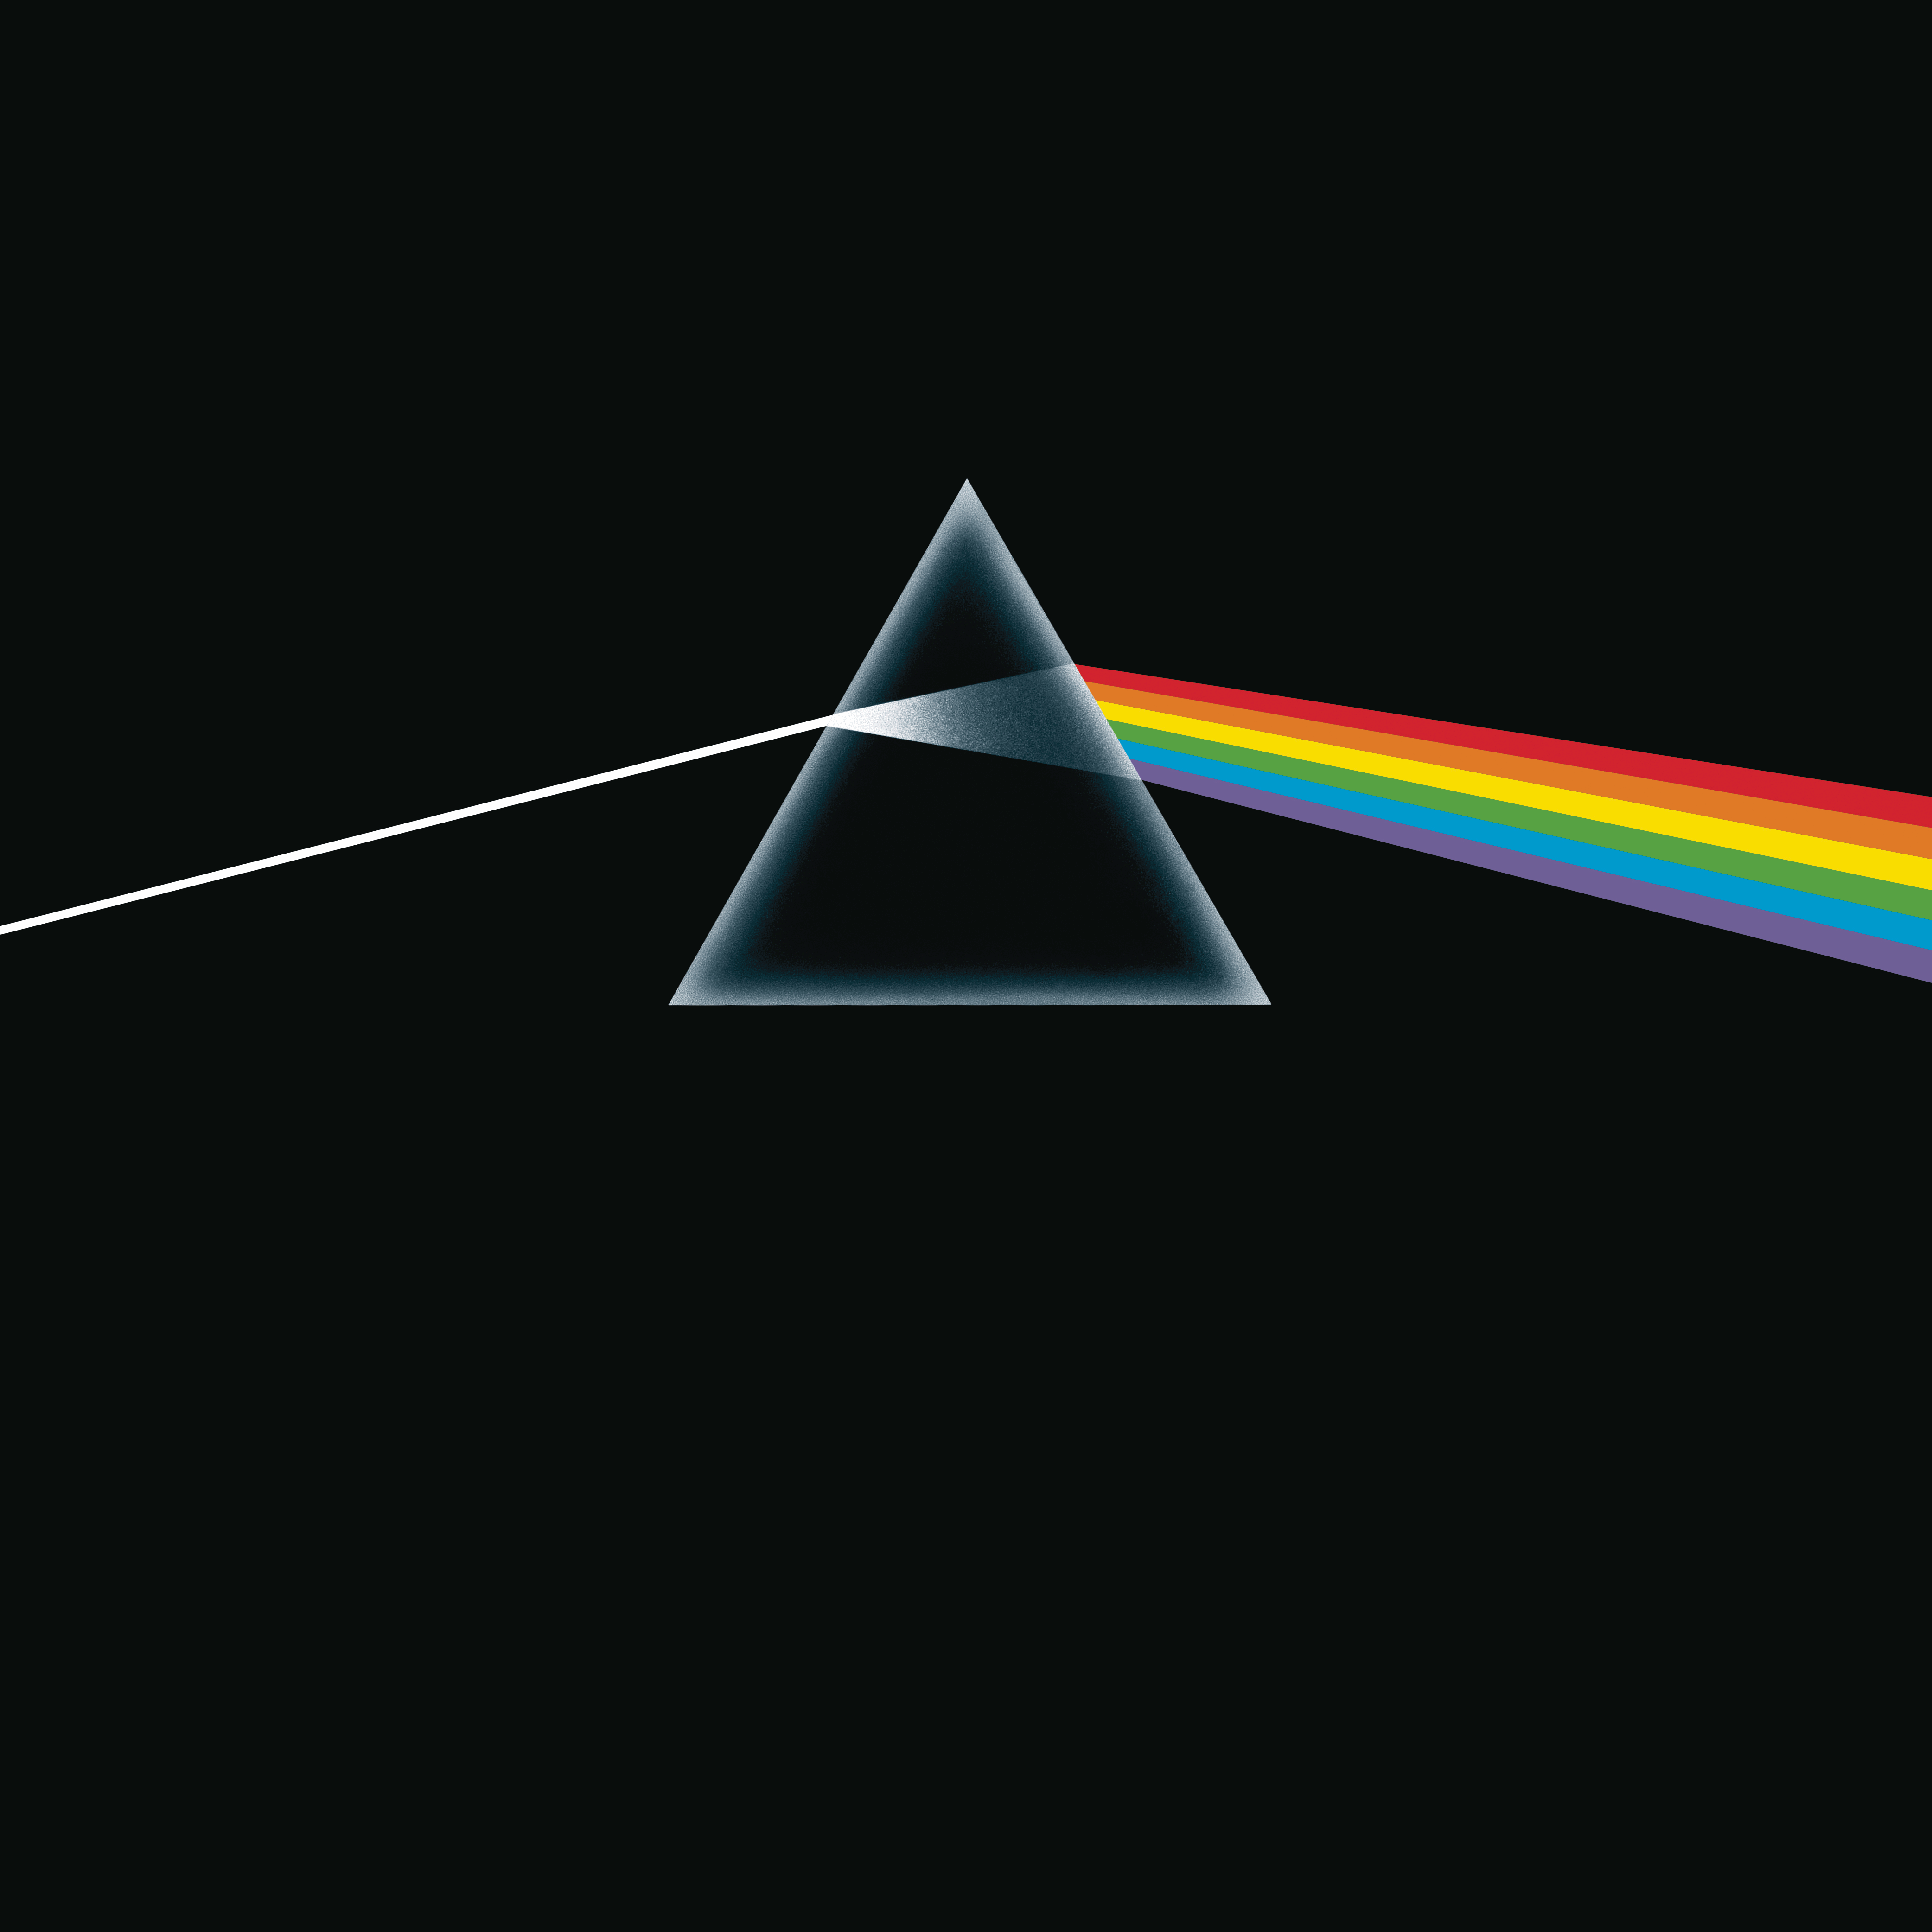


داره یک منشوری را نشان میده که رنگ سفید را به اجزای سازنده اون تبدیل کرده است اون منشوری که وجود داره همون کاری رو می کنه که تبدیل فوریه برای صدا انجام میدهد


### MFCC:

### وارد کردن کتابخانه 

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import GroupKFold, cross_validate, train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.base import clone

from sklearn.metrics import average_precision_score, f1_score

RANDOM_STATE = 42


In [4]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

In [5]:
df = pd.read_csv('/Users/pouniq/music_genre_classification/audio_features/gtzan_5s_features.csv')

In [6]:
mfcc_features = [
    "mfcc1_mean", "mfcc1_var",
    "mfcc2_mean", "mfcc2_var",
    "mfcc3_mean", "mfcc3_var",
    "mfcc4_mean", "mfcc4_var",
    "mfcc5_mean", "mfcc5_var",
    "mfcc6_mean", "mfcc6_var",
    "mfcc7_mean", "mfcc7_var",
    "mfcc8_mean", "mfcc8_var",
    "mfcc9_mean", "mfcc9_var",
    "mfcc10_mean", "mfcc10_var",
    "mfcc11_mean", "mfcc11_var",
    "mfcc12_mean", "mfcc12_var",
    "mfcc13_mean", "mfcc13_var",
    "mfcc14_mean", "mfcc14_var",
    "mfcc15_mean", "mfcc15_var",
    "mfcc16_mean", "mfcc16_var",
    "mfcc17_mean", "mfcc17_var",
    "mfcc18_mean", "mfcc18_var",
    "mfcc19_mean", "mfcc19_var",
    "mfcc20_mean", "mfcc20_var",
    "ber1_mean","ber1_var"
]

In [7]:
X = df.drop(columns=["file", "genre", "segment", "start_sec"])
y = df["genre"]
groups = df["file"]

In [8]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), RandomForestClassifier())

scores = cross_validate(model, X, y, groups=groups, cv=cv,
                        scoring=["accuracy", "f1_macro"])

In [ ]:
print(scores["test_f1_macro"].mean(), scores["test_f1_macro"].std())


0.6992625507789281 0.023906193050865353


In [ ]:
for train, test in cv.split(X, y, groups):
    assert set(groups.iloc[train]).isdisjoint(groups.iloc[test])
    
    
    
X_train = X.iloc[train]
y_train = y.iloc[train]

X_test = X.iloc[test]
y_test = y.iloc[test]

In [21]:
groups.nunique()

999

In [23]:
train

array([   0,    1,    2, ..., 5982, 5983, 5984], shape=(4791,))

In [24]:
test

array([   6,    7,    8, ..., 5964, 5965, 5966], shape=(1194,))

In [25]:
print(X.columns.tolist())

['chroma1_mean', 'chroma1_var', 'chroma2_mean', 'chroma2_var', 'chroma3_mean', 'chroma3_var', 'chroma4_mean', 'chroma4_var', 'chroma5_mean', 'chroma5_var', 'chroma6_mean', 'chroma6_var', 'chroma7_mean', 'chroma7_var', 'chroma8_mean', 'chroma8_var', 'chroma9_mean', 'chroma9_var', 'chroma10_mean', 'chroma10_var', 'chroma11_mean', 'chroma11_var', 'chroma12_mean', 'chroma12_var', 'rms1_mean', 'rms1_var', 'spectral_centroid1_mean', 'spectral_centroid1_var', 'spectral_bandwidth1_mean', 'spectral_bandwidth1_var', 'rolloff1_mean', 'rolloff1_var', 'zcr1_mean', 'zcr1_var', 'contrast1_mean', 'contrast1_var', 'contrast2_mean', 'contrast2_var', 'contrast3_mean', 'contrast3_var', 'contrast4_mean', 'contrast4_var', 'contrast5_mean', 'contrast5_var', 'contrast6_mean', 'contrast6_var', 'contrast7_mean', 'contrast7_var', 'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean', 'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var', 'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_va

## MODEL SELECTION
- SVC
- RF
- LOGISTIC REGRESSION
- NAIVE BAYES


In [28]:
models = {
    'svc': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(random_state=RANDOM_STATE)),
    ]),
    'hgb': Pipeline([
        ('model', HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
    'rf': Pipeline([
        ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    'lg': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    
    'lda': Pipeline(
        [
            ('scaler', StandardScaler()),
            ('model', LinearDiscriminantAnalysis())
        ]
    )
}

In [26]:
y = y.astype('category').cat.codes
y

0       0
1       0
2       0
3       0
4       0
       ..
5980    9
5981    9
5982    9
5983    9
5984    9
Length: 5985, dtype: int8

In [17]:
for name, m in models.items():

    f1 = []

    for train_idx, test_idx in cv.split(X, y, groups=groups):

        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        m.fit(X_train, y_train)
        y_pred = m.predict(X_test)

        score = f1_score(
            y_test,
            y_pred=y_pred,
            average='macro'
        )

        f1.append(score)

    print(f"{name}: {np.mean(f1):.4f} (+/- {np.std(f1):.4f})")

svc: 0.7363 (+/- 0.0192)
hgb: 0.7466 (+/- 0.0229)
rf: 0.7032 (+/- 0.0277)
lg: 0.6846 (+/- 0.0109)
lda: 0.6787 (+/- 0.0151)


In [29]:
import joblib

best_model = clone(models['hgb']).fit(X, y)
joblib.dump(best_model, "saved_models/best_model.joblib")



['saved_models/best_model.joblib']

## Hyper-Parameter Tunning for HGB

In [40]:
from scipy.stats import randint, loguniform
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
param_dist = {
    'model__learning_rate': np.array(loguniform(0.01, 0.3)),
    'model__max_iter': randint(100, 501),
    'model__max_leaf_nodes': [15, 31, 63, 127],
    'model__max_depth': [None, 3, 5, 7, 10],
    'model__min_samples_leaf': randint(10, 51),
    'model__l2_regularization': loguniform(1e-4, 10),
    'model__max_bins': [64, 128, 200, 255],
}

In [56]:
param_grid = {
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [None, 5, 10],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__l2_regularization": [0.0, 0.1, 1.0],
}

hgb_search = GridSearchCV(models['hgb'], param_grid=param_grid, cv=cv, n_jobs=-1)

In [55]:
?GridSearchCV

Init signature:
GridSearchCV(
    estimator,
    param_grid,
    *,
    scoring=None,
    n_jobs=None,
    refit=True,
    cv=None,
    verbose=0,
    pre_dispatch='2*n_jobs',
    error_score=nan,
    return_train_score=False,
)
Docstring:     
Exhaustive search over specified parameter values for an estimator.

Important members are fit, predict.

GridSearchCV implements a "fit" and a "score" method.
It also implements "score_samples", "predict", "predict_proba",
"decision_function", "transform" and "inverse_transform" if they are
implemented in the estimator used.

The parameters of the estimator used to apply these methods are optimized
by cross-validated grid-search over a parameter grid.

Read more in the :ref:`User Guide <grid_search>`.

Parameters
----------
estimator : estimator object
    This is assumed to implement the scikit-learn estimator interface.
    Either estimator needs to provide a ``score`` function,
    or ``scoring`` must be passed.

param_grid : dict or list of

In [53]:
hgb_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__l2_regularization': [0.0, 0.1, ...], 'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [None, 5, ...], 'model__max_leaf_nodes': [15, 31, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 S

In [54]:
hgb_search.best_score_

np.float64(0.6063536085997723)

In [58]:
hgb_search.best_estimator_

AttributeError: 'GridSearchCV' object has no attribute 'best_estimator_'

In [103]:
genre_cat = df["genre"].astype("category")
genre_names = list(genre_cat.cat.categories)

joblib.dump(genre_names, "saved_models/genre_names.joblib")

['saved_models/genre_names.joblib']